# Overview {#sec-pca}




In [1]:
#| code-fold: true
#| code-summary: Code to prepare the environment

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

curfolder = os.getcwd()

# This is where our features live
features = curfolder + '\\Datasets'
dfs = glob.glob(features + '\\*.csv') 

# get sampled_eq_f150.csv
dfs = [df for df in dfs if 'features_all_df_final' in df]
# read the csv file
df = pd.read_csv(dfs[0], index_col=0)
df.head(50)



,concept,handedness,group,RIGHT_INDEX_speed_Gmean,RIGHT_INDEX_speed_Gstd,RIGHT_INDEX_speed_peak_mean,RIGHT_INDEX_speed_peak_std,RIGHT_INDEX_speed_peak_n,RIGHT_INDEX_speed_ipi_avg,RIGHT_INDEX_speed_sampen,...,right_wrist_flex_Gmean,right_wrist_flex_Gstd,right_wrist_flex_peak_mean,right_wrist_flex_peak_std,right_wrist_flex_peak_n,right_wrist_flex_ipi_avg,right_wrist_flex_sampen,right_wrist_flex_integral,right_wrist_flex_ts_range,groupID
fileID,,,,,,,,,,,,,,,,,,,,,
LP28_01_BASKETBALL_body_world,BASKETBALL,1,LP28_01,0.010269,0.009028,0.023490,0.011517,3,866.666667,0.202090,...,120.364924,2.733442,123.278863,2.084460,3,750.000000,0.278761,14326.976005,8.255606,Learners_1
LP28_01_BEINE_body_world,BEINE,NaN,LP28_01,0.005703,0.005895,0.014482,0.008014,3,833.333333,0.161578,...,118.839455,3.099886,123.051987,3.038416,2,1233.333333,0.237410,14143.226975,10.817720,Learners_1
LP28_01_BEOBACHTEN_body_world,BEOBACHTEN,NaN,LP28_01,0.010770,0.011876,0.036217,0.003289,2,1700.000000,0.117509,...,133.169382,16.096814,155.354363,1.008519,2,700.000000,0.068779,15859.037862,40.338420,Learners_1
LP28_01_BEZAHLEN_body_world,BEZAHLEN,NaN,LP28_01,0.010417,0.010947,0.034914,0.002398,2,1866.666667,0.219054,...,128.294358,11.019748,141.240399,6.977965,2,1000.000000,0.119314,15276.441186,31.541555,Learners_1
LP28_01_BIER_body_world,BIER,NaN,LP28_01,0.011722,0.012031,0.032263,0.010759,3,683.333333,0.142563,...,123.696409,9.130901,138.829839,2.529595,2,500.000000,0.064327,14725.106932,24.834981,Learners_1
LP28_01_BILLIARD_body_world,BILLIARD,2a,LP28_01,0.009740,0.009157,0.019035,0.010165,5,408.333333,0.187030,...,124.885691,8.147035,139.754605,NaN,1,NaN,0.138055,14867.595529,23.739553,Learners_1
LP28_01_BODEN_body_world,BODEN,NaN,LP28_01,0.012294,0.011414,0.031798,0.004381,3,700.000000,0.092047,...,122.338377,7.243202,133.212383,3.400720,2,700.000000,0.133929,14562.599166,21.993168,Learners_1
LP28_01_BRECHEN_body_world,BRECHEN,NaN,LP28_01,0.010312,0.011214,0.034958,0.000423,2,1500.000000,0.155625,...,128.366825,12.226039,148.198905,NaN,1,NaN,0.072290,15286.142290,32.020806,Learners_1
LP28_01_BRIEF_body_world,BRIEF,NaN,LP28_01,0.010951,0.011695,0.029014,0.015534,3,750.000000,0.144082,...,126.245166,9.564516,143.319097,NaN,1,NaN,0.073310,15031.084280,26.352933,Learners_1


In [2]:
# Show me proportion of missing values for each column
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0]
print("Proportion of missing values in each column:")
missing_values

Proportion of missing values in each column:


handedness                     92.049355
RIGHT_INDEX_speed_peak_mean     0.009277
RIGHT_INDEX_speed_peak_std      0.510251
RIGHT_INDEX_speed_ipi_avg       0.510251
RIGHT_ELBOW_speed_peak_mean     0.027832
                                 ...    
right_elbow_flex_peak_std       9.388626
right_elbow_flex_ipi_avg        9.388626
right_wrist_flex_peak_mean      0.018555
right_wrist_flex_peak_std      18.127841
right_wrist_flex_ipi_avg       18.127841
Length: 109, dtype: float64

In [3]:
# how many rows if the df have any missing value
rows_with_missing_values = df[df.isnull().any(axis=1)]
print(f"Number of rows with missing values: {len(rows_with_missing_values)}")

Number of rows with missing values: 10508


In [4]:
# how many rows in total?
total_rows = len(df)
print(f"Total number of rows: {total_rows}")

Total number of rows: 10779


In [5]:
# how many columns is there
total_columns = len(df.columns)
print(f"Total number of columns: {total_columns}")

Total number of columns: 347


# Sampling

In [6]:
from math import floor

features_df = df

# get rid of FLESH from df
features_df = features_df[features_df['groupID'] != 'FLESH']
features_df = features_df[features_df['groupID'] != 'test']

# get rid of col handedness
features_df = features_df.drop(columns=['handedness'])

sampled_df_list = []

# Loop through each groupID
for groupID_val in features_df['groupID'].unique():
    sub_df = features_df[features_df['groupID'] == groupID_val]
    unique_groups = sub_df['group'].unique()
    n_groups = len(unique_groups)

    # Calculate how many samples per group to reach total of 150
    per_group_n = floor(250 / n_groups)

    for group_val in unique_groups:
        group_df = sub_df[sub_df['group'] == group_val]

        # Ensure we don’t oversample
        n_to_sample = min(per_group_n, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_df_list.append(sampled)

# Combine all sampled chunks
sampled_df = pd.concat(sampled_df_list).reset_index(drop=True)

    

In [7]:
# how many unique groupID are there?
unique_groupIDs = sampled_df['groupID'].nunique()
print(f"Number of unique groupIDs: {unique_groupIDs}")

# show them
print("Unique groupIDs:")
print(sampled_df['groupID'].unique())

Number of unique groupIDs: 4
Unique groupIDs:
['Learners_1' 'Learners_2' 'DGS' 'Gesture']


In [8]:
sampled_df.head(50)

,concept,group,RIGHT_INDEX_speed_Gmean,RIGHT_INDEX_speed_Gstd,RIGHT_INDEX_speed_peak_mean,RIGHT_INDEX_speed_peak_std,RIGHT_INDEX_speed_peak_n,RIGHT_INDEX_speed_ipi_avg,RIGHT_INDEX_speed_sampen,RIGHT_INDEX_speed_integral,...,right_wrist_flex_Gmean,right_wrist_flex_Gstd,right_wrist_flex_peak_mean,right_wrist_flex_peak_std,right_wrist_flex_peak_n,right_wrist_flex_ipi_avg,right_wrist_flex_sampen,right_wrist_flex_integral,right_wrist_flex_ts_range,groupID
0,UNTERTITEL,LP28_01,0.008571,0.009477,0.029155,0.002749,2,1733.333333,0.162791,1.026558,...,126.550675,7.702750,137.265913,1.449966,2,533.333333,0.108733,15066.475059,20.681580,Learners_1
1,UMZIEHEN,LP28_01,0.012604,0.016807,0.036867,0.010553,2,500.000000,0.034382,1.475739,...,121.267439,9.773547,150.936057,NaN,1,NaN,0.046305,14424.065111,36.603738,Learners_1
2,DUSCHEN,LP28_01,0.018311,0.021438,0.066780,0.003956,2,2133.333333,0.119151,2.184045,...,138.058146,18.459391,159.093517,1.772076,2,1233.333333,0.100786,16444.951873,46.624089,Learners_1
3,HEBEN,LP28_01,0.010282,0.008794,0.023902,0.006278,3,733.333333,0.150669,1.232157,...,122.476567,6.850906,137.015782,NaN,1,NaN,0.113185,14579.469951,21.431254,Learners_1
4,ZERREIẞEN,LP28_01,0.008689,0.008420,0.022462,0.010154,3,1200.000000,0.233680,1.043428,...,125.952984,8.661806,143.186106,NaN,1,NaN,0.155377,14998.190567,27.022515,Learners_1
5,PFLUECKEN,LP28_01,0.008988,0.009204,0.023591,0.011139,3,766.666667,0.094223,1.077265,...,125.387603,8.743620,139.018486,5.252238,2,600.000000,0.115456,14926.930651,26.532604,Learners_1
6,PFANNE,LP28_01,0.007397,0.008048,0.026037,0.002018,2,1800.000000,0.169350,0.885358,...,124.736390,8.290683,135.923870,1.263400,2,900.000000,0.100323,14850.132731,21.808453,Learners_1
7,WEINEN,LP28_01,0.011720,0.013466,0.041545,0.000100,2,2300.000000,0.104303,1.402071,...,134.980107,13.383774,149.915719,1.419839,2,1100.000000,0.087362,16077.568340,34.116560,Learners_1
8,KLAVIER,LP29_01,0.015383,0.008326,0.026080,0.003416,5,608.333333,0.539374,1.840176,...,123.336809,3.323511,127.132669,3.765187,3,1316.666667,0.279645,14679.373966,13.548260,Learners_1
9,MOTORRAD,LP29_01,0.008088,0.006628,0.016549,0.008149,4,1022.222222,0.362905,0.962679,...,123.679278,2.840169,127.649685,3.032107,2,1066.666667,0.269106,14718.775164,10.244629,Learners_1


# PCA: All

Let's start by cleaning the dataframe. In gesture modality, some of the features are not relevant to the current analysis - those are mainly the ones that are related to acoustics and concept-related information. We will remove them from the dataframe before performing PCA.

In [9]:
#| code-fold: true
#| code-summary: Custom functions

# Function to clean the data
def clean_df(df):


    # Fill NaNs with 0
    df = df.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

    # Save values from groupID
    groupID = df['groupID']
    concepts = df['concept']

    # Leave only numerical cols, except groupID
    df = df.select_dtypes(include=['float64','int64'])

    # Add back correction_info
    df['groupID'] = groupID
    df['concept'] = concepts
    
    return df

In [10]:
# Clean the df
df_clean = clean_df(sampled_df)

df_clean.head(15)

,RIGHT_INDEX_speed_Gmean,RIGHT_INDEX_speed_Gstd,RIGHT_INDEX_speed_peak_mean,RIGHT_INDEX_speed_peak_std,RIGHT_INDEX_speed_peak_n,RIGHT_INDEX_speed_ipi_avg,RIGHT_INDEX_speed_sampen,RIGHT_INDEX_speed_integral,RIGHT_INDEX_speed_ts_range,RIGHT_ELBOW_speed_Gmean,...,right_wrist_flex_Gstd,right_wrist_flex_peak_mean,right_wrist_flex_peak_std,right_wrist_flex_peak_n,right_wrist_flex_ipi_avg,right_wrist_flex_sampen,right_wrist_flex_integral,right_wrist_flex_ts_range,groupID,concept
0,0.008571,0.009477,0.029155,0.002749,2,1733.333333,0.162791,1.026558,0.030867,0.002278,...,7.702750,137.265913,1.449966,2,533.333333,0.108733,15066.475059,20.681580,Learners_1,UNTERTITEL
1,0.012604,0.016807,0.036867,0.010553,2,500.000000,0.034382,1.475739,0.070999,0.003666,...,9.773547,150.936057,0.000000,1,0.000000,0.046305,14424.065111,36.603738,Learners_1,UMZIEHEN
2,0.018311,0.021438,0.066780,0.003956,2,2133.333333,0.119151,2.184045,0.068974,0.008626,...,18.459391,159.093517,1.772076,2,1233.333333,0.100786,16444.951873,46.624089,Learners_1,DUSCHEN
3,0.010282,0.008794,0.023902,0.006278,3,733.333333,0.150669,1.232157,0.030477,0.003268,...,6.850906,137.015782,0.000000,1,0.000000,0.113185,14579.469951,21.431254,Learners_1,HEBEN
4,0.008689,0.008420,0.022462,0.010154,3,1200.000000,0.233680,1.043428,0.031898,0.003417,...,8.661806,143.186106,0.000000,1,0.000000,0.155377,14998.190567,27.022515,Learners_1,ZERREIẞEN
5,0.008988,0.009204,0.023591,0.011139,3,766.666667,0.094223,1.077265,0.030297,0.003143,...,8.743620,139.018486,5.252238,2,600.000000,0.115456,14926.930651,26.532604,Learners_1,PFLUECKEN
6,0.007397,0.008048,0.026037,0.002018,2,1800.000000,0.169350,0.885358,0.026897,0.002284,...,8.290683,135.923870,1.263400,2,900.000000,0.100323,14850.132731,21.808453,Learners_1,PFANNE
7,0.011720,0.013466,0.041545,0.000100,2,2300.000000,0.104303,1.402071,0.041119,0.004641,...,13.383774,149.915719,1.419839,2,1100.000000,0.087362,16077.568340,34.116560,Learners_1,WEINEN
8,0.015383,0.008326,0.026080,0.003416,5,608.333333,0.539374,1.840176,0.029725,0.006006,...,3.323511,127.132669,3.765187,3,1316.666667,0.279645,14679.373966,13.548260,Learners_1,KLAVIER
9,0.008088,0.006628,0.016549,0.008149,4,1022.222222,0.362905,0.962679,0.025635,0.004259,...,2.840169,127.649685,3.032107,2,1066.666667,0.269106,14718.775164,10.244629,Learners_1,MOTORRAD


<br>
Now, we first standardize the data and apply PCA to extract principal components. We use custom function  (adapted from [here](https://stackoverflow.com/questions/50796024/feature-variable-importance-after-a-pca-analysis)) to visualize the first two principal components. Data points are color-coded on the target variable (groupID) and red arrows represent the contributions of selected variables to the PC.

## Interactive Biplot

In [125]:
import plotly.graph_objects as go
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

def interactive_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None):
    xs = score[:, 0]
    ys = score[:, 1]

    # Create scatter plot for samples
    scatter = go.Scatter(
        x=xs,
        y=ys,
        mode='markers',
        marker=dict(
            size=8,
            color=y,
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(title='Target')
        ),
        name='Samples',
        text=[f"Sample {i}" for i in range(len(xs))],
        hoverinfo='text'
    )

    # Create arrows for loadings
    arrows = []
    texts = []

    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])

    arrow_scale = 100

    for i in vars_to_plot:

        var_name = f"Var{i+1}" if labels is None else labels[i]
        
        arrows.append(
            go.Scatter(
                x=[0, coeff[i, 0] * arrow_scale],  # scale arrows for visibility
                y=[0, coeff[i, 1] * arrow_scale],
                mode='lines+markers',
                line=dict(color='red'),
                marker=dict(size=3),
                hovertext=var_name,  # FULL NAME here
                hoverinfo='text'
            )
        )
        # texts.append(
        #     go.Scatter(
        #         x=[coeff[i, 0] * 2.2],
        #         y=[coeff[i, 1] * 2.2],
        #         mode='text',
        #         text=[f"Var{i+1}" if labels is None else labels[i]],
        #         textposition='middle right',
        #         showlegend=False
        #     )
        # )

    layout = go.Layout(
        title="Interactive PCA Biplot",
        xaxis=dict(title='PC1'),
        yaxis=dict(title='PC2'),
        width=800,
        height=600,
        hovermode='closest',
        showlegend=False
    )

    fig = go.Figure(data=[scatter] + arrows + texts, layout=layout)
    fig.show()


In [11]:
# make concepts as list
concepts = df_clean['concept'].unique().tolist()
# now get rid of concept col
df_clean = df_clean.drop(columns=['concept'])

In [13]:
# save it
df_clean.to_csv(curfolder + '\\Datasets\\sampled_df_250_cleanforPCA.csv', index=False)

## PC1-PC2

In [127]:
# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X)    

# PCA transformation
pca = PCA()
x_new = pca.fit_transform(X)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings = pca.components_

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(x_new[:, 0:2], np.transpose(pca.components_[0:2, :]),
                       labels=df_clean.columns[:-1], y=y,
                       selected_vars=selected_vars)

## PC2-PC3

In [136]:
interactive_PCA_biplot(score=x_new, 
                       coeff=pca.components_.T, 
                       labels=df_clean.columns[:-1], 
                       y=y,
                       selected_vars=selected_vars, 
                       pc_indices=(1, 2))  

## PCA all: test

In [35]:
# in df_sampled, create column groupID_test, and copy there values from groupID
sampled_df['groupID_test'] = sampled_df['groupID']

# if in column group is string ViCom, replace value in GroupID_test with DGS_2
sampled_df.loc[sampled_df['group'] == 'ViCom', 'groupID_test'] = 'DGS_2'

sampled_df_2 = sampled_df.copy()
# get rid of groupID
sampled_df_2 = sampled_df_2.drop(columns=['groupID'])


In [36]:
sampled_df_2.head()

,concept,group,RIGHT_INDEX_speed_Gmean,RIGHT_INDEX_speed_Gstd,RIGHT_INDEX_speed_peak_mean,RIGHT_INDEX_speed_peak_std,RIGHT_INDEX_speed_peak_n,RIGHT_INDEX_speed_ipi_avg,RIGHT_INDEX_speed_sampen,RIGHT_INDEX_speed_integral,...,right_wrist_flex_Gmean,right_wrist_flex_Gstd,right_wrist_flex_peak_mean,right_wrist_flex_peak_std,right_wrist_flex_peak_n,right_wrist_flex_ipi_avg,right_wrist_flex_sampen,right_wrist_flex_integral,right_wrist_flex_ts_range,groupID_test
0,UNTERTITEL,LP28_01,0.008571,0.009477,0.029155,0.002749,2,1733.333333,0.162791,1.026558,...,126.550675,7.702750,137.265913,1.449966,2,533.333333,0.108733,15066.475059,20.681580,Learners_1
1,UMZIEHEN,LP28_01,0.012604,0.016807,0.036867,0.010553,2,500.000000,0.034382,1.475739,...,121.267439,9.773547,150.936057,NaN,1,NaN,0.046305,14424.065111,36.603738,Learners_1
2,DUSCHEN,LP28_01,0.018311,0.021438,0.066780,0.003956,2,2133.333333,0.119151,2.184045,...,138.058146,18.459391,159.093517,1.772076,2,1233.333333,0.100786,16444.951873,46.624089,Learners_1
3,HEBEN,LP28_01,0.010282,0.008794,0.023902,0.006278,3,733.333333,0.150669,1.232157,...,122.476567,6.850906,137.015782,NaN,1,NaN,0.113185,14579.469951,21.431254,Learners_1
4,ZERREIẞEN,LP28_01,0.008689,0.008420,0.022462,0.010154,3,1200.000000,0.233680,1.043428,...,125.952984,8.661806,143.186106,NaN,1,NaN,0.155377,14998.190567,27.022515,Learners_1


In [38]:
# Function to clean the data
def clean_df2(df):


    # Fill NaNs with 0
    df = df.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

    # Save values from groupID
    groupID = df['groupID_test']
    concepts = df['concept']

    # Leave only numerical cols, except groupID
    df = df.select_dtypes(include=['float64','int64'])

    # Add back correction_info
    df['groupID_test'] = groupID
    df['concept'] = concepts
    
    return df

In [40]:
# Clean the df
df_clean_2 = clean_df2(sampled_df_2)

df_clean_2.head(15)

,RIGHT_INDEX_speed_Gmean,RIGHT_INDEX_speed_Gstd,RIGHT_INDEX_speed_peak_mean,RIGHT_INDEX_speed_peak_std,RIGHT_INDEX_speed_peak_n,RIGHT_INDEX_speed_ipi_avg,RIGHT_INDEX_speed_sampen,RIGHT_INDEX_speed_integral,RIGHT_INDEX_speed_ts_range,RIGHT_ELBOW_speed_Gmean,...,right_wrist_flex_Gstd,right_wrist_flex_peak_mean,right_wrist_flex_peak_std,right_wrist_flex_peak_n,right_wrist_flex_ipi_avg,right_wrist_flex_sampen,right_wrist_flex_integral,right_wrist_flex_ts_range,groupID_test,concept
0,0.008571,0.009477,0.029155,0.002749,2,1733.333333,0.162791,1.026558,0.030867,0.002278,...,7.702750,137.265913,1.449966,2,533.333333,0.108733,15066.475059,20.681580,Learners_1,UNTERTITEL
1,0.012604,0.016807,0.036867,0.010553,2,500.000000,0.034382,1.475739,0.070999,0.003666,...,9.773547,150.936057,0.000000,1,0.000000,0.046305,14424.065111,36.603738,Learners_1,UMZIEHEN
2,0.018311,0.021438,0.066780,0.003956,2,2133.333333,0.119151,2.184045,0.068974,0.008626,...,18.459391,159.093517,1.772076,2,1233.333333,0.100786,16444.951873,46.624089,Learners_1,DUSCHEN
3,0.010282,0.008794,0.023902,0.006278,3,733.333333,0.150669,1.232157,0.030477,0.003268,...,6.850906,137.015782,0.000000,1,0.000000,0.113185,14579.469951,21.431254,Learners_1,HEBEN
4,0.008689,0.008420,0.022462,0.010154,3,1200.000000,0.233680,1.043428,0.031898,0.003417,...,8.661806,143.186106,0.000000,1,0.000000,0.155377,14998.190567,27.022515,Learners_1,ZERREIẞEN
5,0.008988,0.009204,0.023591,0.011139,3,766.666667,0.094223,1.077265,0.030297,0.003143,...,8.743620,139.018486,5.252238,2,600.000000,0.115456,14926.930651,26.532604,Learners_1,PFLUECKEN
6,0.007397,0.008048,0.026037,0.002018,2,1800.000000,0.169350,0.885358,0.026897,0.002284,...,8.290683,135.923870,1.263400,2,900.000000,0.100323,14850.132731,21.808453,Learners_1,PFANNE
7,0.011720,0.013466,0.041545,0.000100,2,2300.000000,0.104303,1.402071,0.041119,0.004641,...,13.383774,149.915719,1.419839,2,1100.000000,0.087362,16077.568340,34.116560,Learners_1,WEINEN
8,0.015383,0.008326,0.026080,0.003416,5,608.333333,0.539374,1.840176,0.029725,0.006006,...,3.323511,127.132669,3.765187,3,1316.666667,0.279645,14679.373966,13.548260,Learners_1,KLAVIER
9,0.008088,0.006628,0.016549,0.008149,4,1022.222222,0.362905,0.962679,0.025635,0.004259,...,2.840169,127.649685,3.032107,2,1066.666667,0.269106,14718.775164,10.244629,Learners_1,MOTORRAD


In [42]:
# make concepts as list
concepts = df_clean_2['concept'].unique().tolist()
# now get rid of concept col
df_clean_2 = df_clean_2.drop(columns=['concept'])

In [48]:
# Prepare data
X = df_clean_2.iloc[:, :-1].values  # All columns except the last as features
y = df_clean_2.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X)    

# PCA transformation
pca = PCA()
x_new = pca.fit_transform(X)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings = pca.components_

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(x_new[:, 0:2], np.transpose(pca.components_[0:2, :]),
                       labels=df_clean_2.columns[:-1], y=y,
                       selected_vars=selected_vars)

In [47]:
print("Unique levels in target column:", np.unique(df_clean_2.iloc[:, -1]))

Unique levels in target column: ['DGS' 'DGS_2' 'Gesture' 'Learners_1' 'Learners_2']


## Interactive 3D plot

In [49]:
import plotly.graph_objects as go
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def interactive_PCA_biplot_3D(score, coeff, labels=None, y=None, selected_vars=None, concept_labels=None):
    xs, ys, zs = score[:, 0], score[:, 1], score[:, 2]

    # Use concept_labels for hover text if provided
    if concept_labels is not None:
        hover_text = [f"Concept: {c}" for c in concept_labels]
    else:
        hover_text = [f"Sample {i}" for i in range(len(xs))]

    # Sample points
    scatter = go.Scatter3d(
        x=xs,
        y=ys,
        z=zs,
        mode='markers',
        marker=dict(
            size=5,
            color=y,
            colorscale='Viridis',
            opacity=0.8,
            colorbar=dict(title='Target')
        ),
        name='Samples',
        hoverinfo='text',
        text=hover_text
    )

    # Arrows (loadings)
    arrows = []

    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    arrow_scale = 100  # smaller in 3D

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        arrows.append(
            go.Scatter3d(
                x=[0, coeff[i, 0] * arrow_scale],
                y=[0, coeff[i, 1] * arrow_scale],
                z=[0, coeff[i, 2] * arrow_scale],
                mode='lines+markers',
                line=dict(color='red', width=4),
                marker=dict(size=3),
                hovertext=var_name,
                hoverinfo='text',
                name=var_name
            )
        )

    layout = go.Layout(
        title="Interactive 3D PCA Biplot",
        scene=dict(
            xaxis_title="PC1",
            yaxis_title="PC2",
            zaxis_title="PC3"
        ),
        width=900,
        height=700,
        showlegend=False
    )

    fig = go.Figure(data=[scatter] + arrows, layout=layout)
    fig.show()


In [51]:
# Prepare data
X = df_clean_2.iloc[:, :-1].values  # All columns except the last as features
y = df_clean_2.iloc[:, -1].values   # Last column as target variable

print("Unique levels in target column:", np.unique(df_clean_2.iloc[:, -1]))

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels
    y_encoded = le.fit_transform(y)
    print(dict(zip(le.classes_, le.transform(le.classes_))))

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X)    

# PCA transformation
pca = PCA()
x_new = pca.fit_transform(X)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings = pca.components_.T

# Get top variables per PC by absolute contribution
top_n = 5
top_vars = set()
for i in range(3):  # for PC1, PC2, PC3
    component = loadings[:, i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

interactive_PCA_biplot_3D(
    score=x_new,
    coeff=loadings,
    labels=df_clean_2.columns[:-1],
    y=y,
    selected_vars=selected_vars,  # top 10 contributors
    concept_labels=concepts
)

Unique levels in target column: ['DGS' 'DGS_2' 'Gesture' 'Learners_1' 'Learners_2']
{0: 0, 1: 1, 2: 2, 3: 3, 4: 4}


<br>
What amount of variances each PC explains?

In [52]:
#| echo: false

pca.explained_variance_ratio_

array([2.02231828e-01, 1.42497550e-01, 8.89953522e-02, 5.78989988e-02,
       3.84700418e-02, 3.15408524e-02, 2.73967189e-02, 1.99465060e-02,
       1.83953819e-02, 1.82489129e-02, 1.60716983e-02, 1.37070842e-02,
       1.15946682e-02, 9.92341369e-03, 9.41183444e-03, 8.79848087e-03,
       7.75194094e-03, 7.11619680e-03, 6.80073546e-03, 6.47455470e-03,
       6.38289745e-03, 5.98283078e-03, 5.47293381e-03, 5.28527930e-03,
       5.07001167e-03, 4.88157043e-03, 4.65901224e-03, 4.60075940e-03,
       4.53709712e-03, 4.38967462e-03, 4.19930477e-03, 3.97881470e-03,
       3.94580933e-03, 3.79934085e-03, 3.71032085e-03, 3.64346262e-03,
       3.53511515e-03, 3.43162372e-03, 3.33095831e-03, 3.23351944e-03,
       3.13195539e-03, 3.06274960e-03, 3.00215937e-03, 2.92893138e-03,
       2.79020607e-03, 2.75535222e-03, 2.70961363e-03, 2.69091781e-03,
       2.66938220e-03, 2.54219146e-03, 2.50357459e-03, 2.45996356e-03,
       2.43946316e-03, 2.36575484e-03, 2.33478691e-03, 2.25561366e-03,
      

<br>
First explains 19.7, second 13.7, third 10.3 % of variance. The rest explains less than 6 % each

Now we can check the most important features. The larger the absolute value of the Eigenvalue, the more important the feature is for the principal component.

In [53]:
#| echo: false

print(abs( pca.components_ ))

[[9.75234026e-02 8.12135595e-02 8.47073082e-02 ... 5.68085572e-02
  9.29954839e-02 1.24112200e-03]
 [1.07662710e-02 1.64646875e-02 6.61350076e-03 ... 2.30409384e-02
  7.17239605e-02 3.01753864e-02]
 [6.16293941e-02 1.06861048e-01 9.75003421e-02 ... 4.44724303e-02
  4.77376955e-02 7.96309527e-02]
 ...
 [3.09159220e-02 1.03061874e-01 4.65803220e-03 ... 1.17637564e-03
  3.17127052e-02 2.86980041e-04]
 [1.11800659e-01 5.55178660e-02 8.98582268e-03 ... 8.61909364e-04
  3.84737840e-02 1.61965660e-03]
 [3.13743333e-01 1.48203466e-02 3.02275239e-03 ... 1.26679752e-04
  4.03077941e-02 2.47294443e-03]]


In [55]:
# Number of principal components
n_pcs = 3

# Feature names (excluding target column)
feature_names = df_clean_2.columns[:-1]  

# Create storage for the ordered feature names and loadings
results_dict = {}

for i in range(n_pcs):
    # Get all features sorted by absolute loading values
    sorted_indices = np.abs(pca.components_[i]).argsort()[::-1]
    sorted_features = feature_names[sorted_indices]  # Feature names
    sorted_loadings = pca.components_[i, sorted_indices]  # Loadings

    # Store in dictionary
    results_dict[f'PC{i+1}'] = sorted_features.values
    results_dict[f'PC{i+1}_Loading'] = sorted_loadings

# Convert dictionary to DataFrame
results_df = pd.DataFrame(results_dict)
results_df.head(50)


,PC1,PC1_Loading,PC2,PC2_Loading,PC3,PC3_Loading
0,total_arm_acceleration_Gmean,0.111423,LEFT_WRIST_speed_integral,0.128248,rwrist_rhip_Gstd,0.131607
1,total_arm_jerk_Gmean,0.110254,LEFT_INDEX_speed_integral,0.126078,rwrist_rhip_peak_mean,0.131271
2,total_arm_jerk_peak_mean,0.102707,LEFT_ELBOW_speed_integral,0.124969,rwrist_rhip_ts_range,0.129331
3,total_arm_speed_Gmean,0.100587,total_arm_speed_integral,0.124382,arm_asymmetry,-0.128450
4,total_arm_acceleration_peak_mean,0.098670,total_arm_acceleration_integral,0.121637,rwrist_lhip_Gstd,0.124678
5,total_arm_acceleration_Gstd,0.098414,lwrist_lhip_ts_range,0.117391,rwrist_lhip_ts_range,0.123067
6,rwrist_rshoulder_integral,-0.098248,lwrist_rhip_ts_range,0.115890,RIGHT_WRIST_speed_ts_range,0.122864
7,RIGHT_INDEX_speed_Gmean,0.097523,total_arm_jerk_integral,0.113960,rwrist_lhip_peak_mean,0.117921
8,lwrist_nose_integral,-0.097123,RIGHT_ELBOW_speed_integral,0.112703,RIGHT_INDEX_speed_ts_range,0.117132
9,total_arm_speed_peak_mean,0.096916,left_arm_flex_ts_range,0.110896,RIGHT_WRIST_speed_Gstd,0.114232


# PCA: gesture vs sign

In [14]:
from math import floor

df_GS = df

# get rid of FLESH from df
df_GS = df_GS[df_GS['groupID'] != 'FLESH']
df_GS = df_GS[df_GS['groupID'] != 'test']

# get rid of col handedness
df_GS = df_GS.drop(columns=['handedness'])

# create column systemID, if Gesture in groupID, then systemID==Gesture, else Sign
df_GS['systemID'] = df_GS['groupID'].apply(lambda x: 'Gesture' if 'Gesture' in x else 'Sign')

sampled_GS_list = []

# Loop through each groupID
for groupID_val in df_GS['systemID'].unique():
    sub_df = df_GS[df_GS['systemID'] == groupID_val]
    unique_groups = sub_df['group'].unique()
    n_groups = len(unique_groups)

    # Calculate how many samples per group to reach total of 150
    per_group_n = floor(250 / n_groups)

    for group_val in unique_groups:
        group_df = sub_df[sub_df['group'] == group_val]

        # Ensure we don’t oversample
        n_to_sample = min(per_group_n, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_GS_list.append(sampled)

# Combine all sampled chunks
sampled_GS = pd.concat(sampled_GS_list).reset_index(drop=True)

    

In [15]:
# Fill NaNs with 0
sampled_GS = sampled_GS.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

# Save values from groupID
systemID = sampled_GS['systemID']
concepts = sampled_GS['concept']

# Leave only numerical cols, except groupID
sampled_GS = sampled_GS.select_dtypes(include=['float64','int64'])

# Add back correction_info
sampled_GS['systemID'] = systemID



In [16]:
# save it
sampled_GS.to_csv(curfolder + '\\Datasets\\sampled_GS_df_250_cleanforPCA.csv', index=False)

In [128]:
def interactive_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None, pc_indices=(0, 1)):
    """
    Creates an interactive PCA biplot using Plotly.

    Parameters:
    - score: np.array, transformed data (e.g., result of PCA().fit_transform(X))
    - coeff: np.array, loadings (e.g., PCA().components_.T)
    - labels: list, variable names (default: Var1, Var2, ...)
    - y: array-like, coloring variable for data points
    - selected_vars: list of indices of variables to plot as arrows
    - pc_indices: tuple, which principal components to plot (e.g., (0, 1) for PC1 vs PC2)
    """
    pc_x, pc_y = pc_indices

    xs = score[:, pc_x]
    ys = score[:, pc_y]

    # Scatter for data points
    scatter = go.Scatter(
        x=xs,
        y=ys,
        mode='markers',
        marker=dict(
            size=8,
            color=y,
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(title='Target')
        ),
        name='Samples',
        text=[f"Sample {i}" for i in range(len(xs))],
        hoverinfo='text'
    )

    # Arrows for variable loadings
    arrows = []
    texts = []
    arrow_scale = 100
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]

        arrows.append(
            go.Scatter(
                x=[0, coeff[i, pc_x] * arrow_scale],
                y=[0, coeff[i, pc_y] * arrow_scale],
                mode='lines+markers',
                line=dict(color='red'),
                marker=dict(size=3),
                hovertext=var_name,
                hoverinfo='text'
            )
        )

    layout = go.Layout(
        title=f"Interactive PCA Biplot (PC{pc_x+1} vs PC{pc_y+1})",
        xaxis=dict(title=f'PC{pc_x+1}'),
        yaxis=dict(title=f'PC{pc_y+1}'),
        width=800,
        height=600,
        hovermode='closest',
        showlegend=False
    )

    fig = go.Figure(data=[scatter] + arrows + texts, layout=layout)
    fig.show()


## PC1-PC2 biplot

In [110]:
# Prepare data
X = sampled_GS.iloc[:, :-1].values  # All columns except the last as features
y = sampled_GS.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X)    

# PCA transformation
pca = PCA()
x_new = pca.fit_transform(X)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings = pca.components_

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(x_new[:, 0:2], np.transpose(pca.components_[0:2, :]),
                       labels=sampled_GS.columns[:-1], y=y,
                       selected_vars=selected_vars, pc_indices=(0, 1))

## PC2-PC3 biplot

In [ ]:
interactive_PCA_biplot(score=x_new, 
                       coeff=pca.components_.T, 
                       labels=sampled_GS.columns[:-1], 
                       y=y,
                       selected_vars=selected_vars, 
                       pc_indices=(1, 2))  

## 3d plot

In [111]:

interactive_PCA_biplot_3D(
    score=x_new,
    coeff=loadings,
    labels=sampled_GS.columns[:-1],
    y=y,
    selected_vars=selected_vars,  # top 10 contributors
    concept_labels=concepts
)

In [61]:
print("Unique levels in target column:", np.unique(sampled_GS.iloc[:, -1]))

Unique levels in target column: ['Gesture' 'Sign']


## How many PCs

In [65]:
def get_PCA(df):
    # Step 1: Standardize the Data
    scaler = StandardScaler()
    standardized_data = scaler.fit_transform(df)
    
    # Step 2: Apply PCA
    pca = PCA()
    pca.fit(standardized_data)
    
    # Step 3: Explained Variance
    explained_variance = pca.explained_variance_ratio_
    cumulative_explained_variance = explained_variance.cumsum()

    # Step 4: Find the number of components that explain 95% variance
    n_components_for_80_variance = np.argmax(cumulative_explained_variance >= 0.8) + 1
    
    # Step 5: Compute the slope for the first n_components_for_95_variance
    if n_components_for_80_variance > 1:
        slope_80 = (cumulative_explained_variance[n_components_for_80_variance-1] - cumulative_explained_variance[0]) / (n_components_for_80_variance - 1)
    else:
        slope_80 = cumulative_explained_variance[0]  # Only one component case

    # 95% variance
    n_components_for_95_variance = np.argmax(cumulative_explained_variance >= 0.95) + 1
    
    # Step 5: Compute the slope for the first n_components_for_95_variance
    if n_components_for_95_variance > 1:
        slope_95 = (cumulative_explained_variance[n_components_for_95_variance-1] - cumulative_explained_variance[0]) / (n_components_for_95_variance - 1)
    else:
        slope_95 = cumulative_explained_variance[0]  # Only one component case


    #Optionally plot the cumulative explained variance
    plt.figure(figsize=(8, 6))
    plt.plot(cumulative_explained_variance, marker='o', label='Cumulative Explained Variance')
    plt.axvline(x=n_components_for_80_variance-1, color='red', linestyle='--', label=f'80% Variance at {n_components_for_80_variance} components')
    plt.axvline(x=n_components_for_95_variance-1, color='green', linestyle='--', label=f'95% Variance at {n_components_for_95_variance} components')
    plt.xlabel('Number of Principal Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('Cumulative Explained Variance by PCA')
    plt.grid(True)
    plt.legend()
    plt.show()

    return n_components_for_80_variance, slope_80, n_components_for_95_variance, slope_95


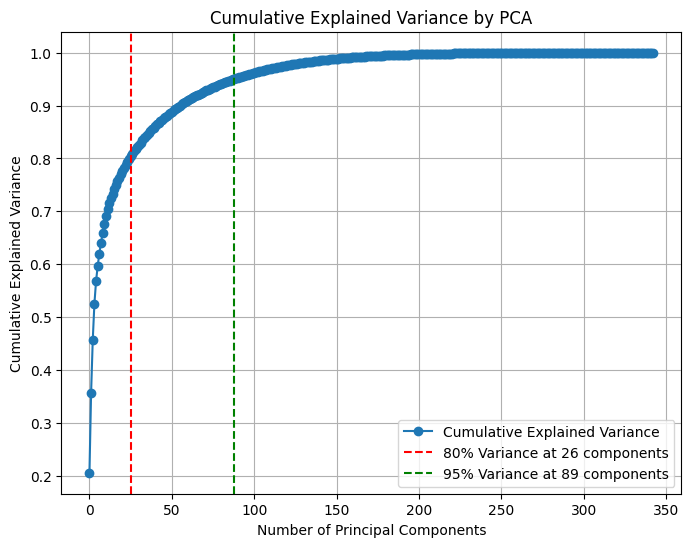

(26, 0.02391949970747602, 89, 0.008464279283570802)

In [66]:
# scree plot
get_PCA(sampled_GS.iloc[:, :-1])

## Variance explained

In [ ]:
pca.explained_variance_ratio_

array([2.05841204e-01, 1.51430596e-01, 9.99545652e-02, 6.82489812e-02,
       4.25471739e-02, 2.87879733e-02, 2.35343720e-02, 2.02198923e-02,
       1.88555852e-02, 1.66411860e-02, 1.50802753e-02, 1.25263272e-02,
       1.14075511e-02, 9.45800725e-03, 9.01491369e-03, 8.25285204e-03,
       7.96773112e-03, 7.21760511e-03, 7.04131543e-03, 6.79455711e-03,
       6.26611814e-03, 5.67710672e-03, 5.63426224e-03, 5.29046204e-03,
       5.10244247e-03, 5.03564089e-03, 4.99207651e-03, 4.48333368e-03,
       4.37034447e-03, 4.32821581e-03, 4.20148115e-03, 4.01583587e-03,
       3.83245700e-03, 3.78635767e-03, 3.59181797e-03, 3.53246572e-03,
       3.41307260e-03, 3.37318460e-03, 3.32464247e-03, 3.26447118e-03,
       3.17725009e-03, 2.98391940e-03, 2.92670902e-03, 2.86283060e-03,
       2.84180097e-03, 2.72608388e-03, 2.67395173e-03, 2.63400678e-03,
       2.46953313e-03, 2.46417123e-03, 2.41410389e-03, 2.40787392e-03,
       2.32996453e-03, 2.30009770e-03, 2.25826090e-03, 2.20314159e-03,
      

## Feature importance

In [67]:
# Number of principal components
n_pcs = 5

# Feature names (excluding target column)
feature_names = sampled_GS.columns[:-1]  

# Create storage for the ordered feature names and loadings
results_dict = {}

for i in range(n_pcs):
    # Get all features sorted by absolute loading values
    sorted_indices = np.abs(pca.components_[i]).argsort()[::-1]
    sorted_features = feature_names[sorted_indices]  # Feature names
    sorted_loadings = pca.components_[i, sorted_indices]  # Loadings

    # Store in dictionary
    results_dict[f'PC{i+1}'] = sorted_features.values
    results_dict[f'PC{i+1}_Loading'] = sorted_loadings

# Convert dictionary to DataFrame
results_GS = pd.DataFrame(results_dict)
results_GS.head(50)


,PC1,PC1_Loading,PC2,PC2_Loading,PC3,PC3_Loading,PC4,PC4_Loading,PC5,PC5_Loading
0,total_arm_acceleration_Gmean,0.107746,rwrist_lshoulder_integral,-0.129648,arm_asymmetry,-0.144358,LEFT_INDEX_speed_sampen,0.173476,LEFT_WRIST_acceleration_Gmean,0.201374
1,total_arm_speed_Gstd,0.106662,left_wrist_flex_integral,-0.129553,right_wrist_flex_peak_mean,0.117297,total_arm_speed_sampen,0.172426,LEFT_WRIST_acceleration_integral,0.197623
2,total_arm_speed_Gmean,0.106586,right_wrist_flex_integral,-0.129179,RIGHT_WRIST_acceleration_peak_std,0.115032,LEFT_WRIST_speed_sampen,0.171056,LEFT_INDEX_acceleration_Gmean,0.194104
3,total_arm_speed_peak_mean,0.106553,rwrist_rshoulder_integral,-0.127006,RIGHT_INDEX_speed_ts_range,0.113485,LEFT_INDEX_acceleration_sampen,0.165878,LEFT_INDEX_acceleration_integral,0.193886
4,total_arm_speed_ts_range,0.104028,lwrist_rshoulder_integral,-0.125414,RIGHT_INDEX_speed_Gstd,0.112633,LEFT_WRIST_acceleration_sampen,0.164948,LEFT_WRIST_jerk_integral,0.183871
5,total_arm_jerk_Gmean,0.102690,right_elbow_flex_integral,-0.121110,RIGHT_INDEX_acceleration_ts_range,0.112386,total_arm_acceleration_sampen,0.159753,LEFT_INDEX_jerk_integral,0.182647
6,total_arm_jerk_peak_mean,0.101281,rwrist_lhip_integral,-0.120690,RIGHT_INDEX_acceleration_peak_std,0.112300,LEFT_ELBOW_speed_sampen,0.153944,RIGHT_WRIST_acceleration_Gmean,0.179314
7,LEFT_ELBOW_acceleration_Gstd,0.099604,LEFT_ELBOW_jerk_peak_n,-0.118859,RIGHT_WRIST_speed_Gstd,0.111944,RIGHT_WRIST_speed_sampen,0.152413,LEFT_INDEX_jerk_Gmean,0.174584
8,LEFT_ELBOW_speed_Gmean,0.099155,RIGHT_WRIST_jerk_peak_n,-0.118326,rwrist_nose_Gstd,0.110653,RIGHT_INDEX_speed_sampen,0.149939,RIGHT_INDEX_acceleration_Gmean,0.173727
9,LEFT_ELBOW_speed_peak_mean,0.099074,RIGHT_INDEX_jerk_peak_n,-0.118288,RIGHT_WRIST_speed_peak_mean,0.110630,LEFT_INDEX_jerk_sampen,0.148624,LEFT_WRIST_jerk_Gmean,0.173662


# PCA: Native signer vs non-native signer

In [17]:
from math import floor

df_NN = df

# get rid of FLESH from df
df_NN = df_NN[df_NN['groupID'] != 'FLESH']
df_NN = df_NN[df_NN['groupID'] != 'test']

# get rid of col handedness
df_NN = df_NN.drop(columns=['handedness'])

# create column profID, if DGS in groupID, then profID==native, if Learners_1==non1, if Learners_2==non2, else Nan
df_NN['profID'] = df_NN['groupID'].apply(
    lambda x: 'native' if 'DGS' in x else ('non1' if 'Learners_1' in x else ('non2' if 'Learners_2' in x else np.nan))
)

# get rid of groupID==Gesture
df_NN = df_NN[df_NN['groupID'] != 'Gesture']

sampled_NN_list = []

# Loop through each groupID
for groupID_val in df_NN['profID'].unique():
    sub_df = df_NN[df_NN['profID'] == groupID_val]
    unique_groups = sub_df['group'].unique()
    n_groups = len(unique_groups)

    # Calculate how many samples per group to reach total of 150
    per_group_n = floor(250 / n_groups)

    for group_val in unique_groups:
        group_df = sub_df[sub_df['group'] == group_val]

        # Ensure we don’t oversample
        n_to_sample = min(per_group_n, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_NN_list.append(sampled)

# Combine all sampled chunks
sampled_NN = pd.concat(sampled_NN_list).reset_index(drop=True)

    

In [18]:
# Fill NaNs with 0
sampled_NN = sampled_NN.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

# Save values from groupID
profID = sampled_NN['profID']
concepts = sampled_NN['concept']

# Leave only numerical cols, except groupID
sampled_NN = sampled_NN.select_dtypes(include=['float64','int64'])

# Add back correction_info
sampled_NN['profID'] = profID



In [19]:
# save it
sampled_NN.to_csv(curfolder + '\\Datasets\\sampled_NN_df_250_cleanforPCA.csv', index=False)

In [140]:
# Prepare data
X = sampled_NN.iloc[:, :-1].values  # All columns except the last as features
y = sampled_NN.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X)    

# PCA transformation
pca = PCA()
x_new = pca.fit_transform(X)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings = pca.components_

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

## PC1-PC2 biplot

In [141]:
print("Unique levels in target column:", np.unique(sampled_NN.iloc[:, -1]))

Unique levels in target column: ['native' 'non1' 'non2']


In [142]:
interactive_PCA_biplot(score=x_new, 
                       coeff=pca.components_.T, 
                       labels=sampled_NN.columns[:-1], 
                       y=y,
                       selected_vars=selected_vars, 
                       pc_indices=(0, 1))  # plot PC1 vs PC3

## PC2-PC3 biplot

In [143]:
interactive_PCA_biplot(score=x_new, 
                       coeff=pca.components_.T, 
                       labels=sampled_NN.columns[:-1], 
                       y=y,
                       selected_vars=selected_vars, 
                       pc_indices=(1, 2)) 

## 3d plot

In [144]:

interactive_PCA_biplot_3D(
    score=x_new,
    coeff=loadings,
    labels=sampled_NN.columns[:-1],
    y=y,
    selected_vars=selected_vars,  # top 10 contributors
    concept_labels=concepts
)

## How many components in total

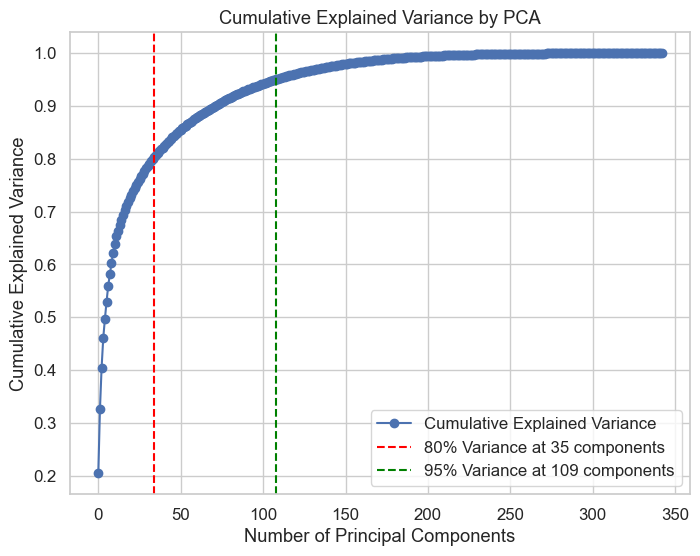

(35, 0.017607073528281777, 109, 0.0069090953477385815)

In [145]:
get_PCA(sampled_NN.iloc[:, :-1])

## Variance explained

In [93]:
pca.explained_variance_ratio_

array([2.04445523e-01, 1.21438994e-01, 7.88249102e-02, 5.59407120e-02,
       3.60222111e-02, 3.28994688e-02, 2.96343698e-02, 2.21708871e-02,
       2.12918711e-02, 1.96276322e-02, 1.58323977e-02, 1.47825949e-02,
       1.11247611e-02, 1.07288307e-02, 9.81850489e-03, 9.41179790e-03,
       8.47621119e-03, 8.23929780e-03, 7.53717710e-03, 7.14724630e-03,
       6.85354930e-03, 6.39177959e-03, 6.33984946e-03, 5.89603050e-03,
       5.57414106e-03, 5.34539167e-03, 5.26828350e-03, 5.15297283e-03,
       4.92464811e-03, 4.71466796e-03, 4.57605628e-03, 4.36518647e-03,
       4.23562023e-03, 4.10329754e-03, 3.94914946e-03, 3.82133767e-03,
       3.77598823e-03, 3.62247665e-03, 3.56405655e-03, 3.51013896e-03,
       3.45731058e-03, 3.30064964e-03, 3.21566751e-03, 3.15783051e-03,
       3.10980014e-03, 3.04491512e-03, 2.92652029e-03, 2.87807878e-03,
       2.85239263e-03, 2.78628490e-03, 2.73083793e-03, 2.63739946e-03,
       2.60252048e-03, 2.58616138e-03, 2.51221581e-03, 2.43236058e-03,
      

## Feature importance

In [94]:
# Number of principal components
n_pcs = 5

# Feature names (excluding target column)
feature_names = sampled_NN.columns[:-1]  

# Create storage for the ordered feature names and loadings
results_dict = {}

for i in range(n_pcs):
    # Get all features sorted by absolute loading values
    sorted_indices = np.abs(pca.components_[i]).argsort()[::-1]
    sorted_features = feature_names[sorted_indices]  # Feature names
    sorted_loadings = pca.components_[i, sorted_indices]  # Loadings

    # Store in dictionary
    results_dict[f'PC{i+1}'] = sorted_features.values
    results_dict[f'PC{i+1}_Loading'] = sorted_loadings

# Convert dictionary to DataFrame
results_NN = pd.DataFrame(results_dict)
results_NN.head(50)

,PC1,PC1_Loading,PC2,PC2_Loading,PC3,PC3_Loading,PC4,PC4_Loading,PC5,PC5_Loading
0,total_arm_acceleration_Gmean,0.112308,LEFT_INDEX_speed_integral,0.140457,RIGHT_WRIST_speed_integral,0.149874,total_arm_speed_sampen,0.178019,LEFT_WRIST_acceleration_integral,0.183250
1,total_arm_jerk_Gmean,0.111470,LEFT_WRIST_speed_integral,0.139360,rwrist_rhip_peak_mean,0.149633,RIGHT_WRIST_speed_sampen,0.170232,LEFT_WRIST_jerk_integral,0.181649
2,total_arm_jerk_peak_mean,0.104994,lwrist_rhip_ts_range,0.130752,rwrist_lhip_ts_range,0.144683,RIGHT_INDEX_speed_sampen,0.167038,LEFT_INDEX_jerk_integral,0.173545
3,rwrist_rshoulder_integral,-0.102490,lwrist_rhip_peak_mean,0.130059,rwrist_rhip_ts_range,0.142470,RIGHT_INDEX_acceleration_sampen,0.166633,LEFT_INDEX_acceleration_integral,0.170894
4,lwrist_nose_integral,-0.102056,lwrist_lhip_peak_mean,0.128913,RIGHT_INDEX_speed_integral,0.141776,total_arm_acceleration_sampen,0.165892,LEFT_ELBOW_acceleration_integral,0.168938
5,total_arm_speed_Gmean,0.101333,lwrist_nose_ts_range,0.125615,rwrist_rhip_Gstd,0.139835,RIGHT_WRIST_acceleration_sampen,0.162676,LEFT_ELBOW_jerk_integral,0.165835
6,total_arm_acceleration_Gstd,0.101253,lwrist_rhip_Gstd,0.125176,rwrist_lhip_Gstd,0.138367,LEFT_WRIST_speed_sampen,0.159707,LEFT_ELBOW_acceleration_Gmean,0.165434
7,total_arm_acceleration_peak_mean,0.100724,lwrist_lshoulder_ts_range,0.124476,rwrist_lhip_peak_mean,0.137126,LEFT_INDEX_speed_sampen,0.156920,LEFT_WRIST_acceleration_Gmean,0.165335
8,lwrist_rshoulder_integral,-0.100615,LEFT_INDEX_speed_ts_range,0.123993,rwrist_rhip_Gmean,0.131281,LEFT_WRIST_acceleration_sampen,0.153878,LEFT_WRIST_jerk_Gmean,0.163659
9,right_elbow_flex_integral,-0.100525,left_elbow_flex_ts_range,0.123467,right_arm_flex_integral,0.129351,LEFT_INDEX_acceleration_sampen,0.153624,LEFT_INDEX_jerk_Gmean,0.156052


# Visualizing

In [95]:
# get first three rows from results GS and NN
features_GS = results_GS.iloc[:3, :].copy()
features_NN = results_NN.iloc[:3, :].copy()


## Gesture vs sign

In [96]:
features_GS

,PC1,PC1_Loading,PC2,PC2_Loading,PC3,PC3_Loading,PC4,PC4_Loading,PC5,PC5_Loading
0,total_arm_acceleration_Gmean,0.107746,rwrist_lshoulder_integral,-0.129648,arm_asymmetry,-0.144358,LEFT_INDEX_speed_sampen,0.173476,LEFT_WRIST_acceleration_Gmean,0.201374
1,total_arm_speed_Gstd,0.106662,left_wrist_flex_integral,-0.129553,right_wrist_flex_peak_mean,0.117297,total_arm_speed_sampen,0.172426,LEFT_WRIST_acceleration_integral,0.197623
2,total_arm_speed_Gmean,0.106586,right_wrist_flex_integral,-0.129179,RIGHT_WRIST_acceleration_peak_std,0.115032,LEFT_WRIST_speed_sampen,0.171056,LEFT_INDEX_acceleration_Gmean,0.194104


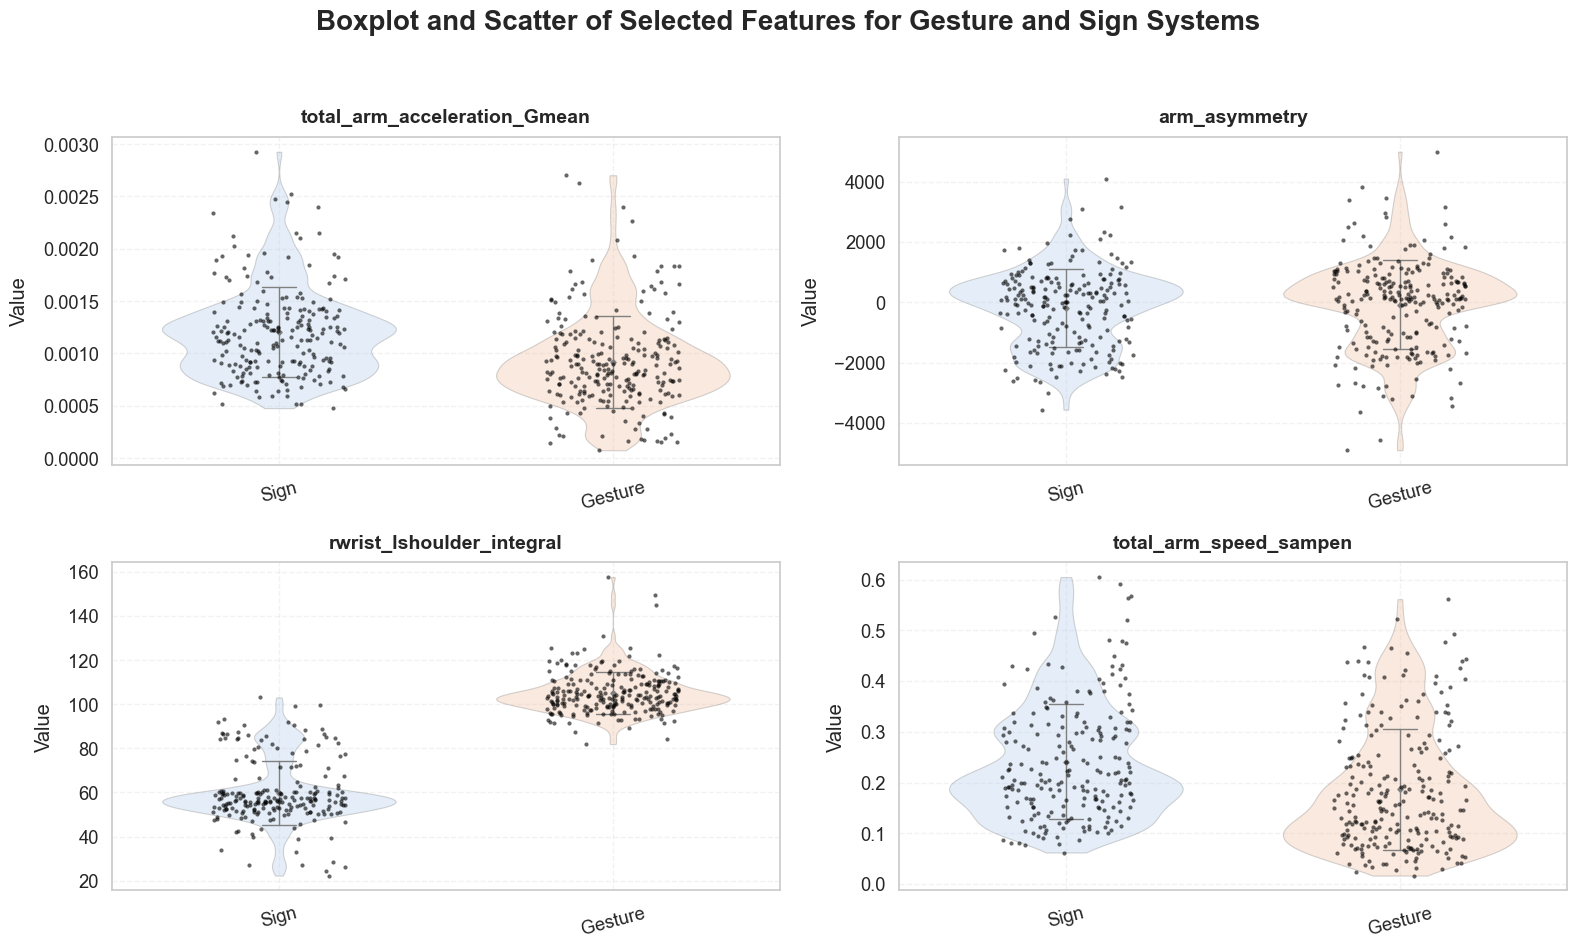

In [152]:
import seaborn as sns
# ignore warnings
import warnings
warnings.filterwarnings("ignore")

featstoplotGS = ['total_arm_acceleration_Gmean',
                 'arm_asymmetry',
                 'rwrist_lshoulder_integral',
                 'total_arm_speed_sampen']

def plot_features_halfviolin_scatter(df, features, title):
    sns.set_theme(style="whitegrid", font_scale=1.2)
    palette = sns.color_palette("pastel", df['systemID'].nunique())

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
    axes = axes.flatten()

    for i, feature in enumerate(features):
        ax = axes[i]

        # Violin with lighter fill
        sns.violinplot(
            data=df, x='systemID', y=feature, ax=ax,
            palette=palette,
            inner=None, cut=0, linewidth=0.8, scale='width',
            bw=.2, orient='v', width=0.7
        )

        # Make violins slightly transparent
        for violin in ax.collections:
            violin.set_alpha(0.3)

        # Swarm or improved strip plot
        sns.stripplot(
            data=df, x='systemID', y=feature, ax=ax,
            jitter=0.2, dodge=True, color='black', alpha=0.6, size=3
        )

        # Optional: median line using pointplot
        sns.pointplot(
            data=df, x='systemID', y=feature, ax=ax,
            color='gray', ci='sd', join=False, markers='D',
            scale=0.5, errwidth=1, capsize=0.1
        )

        ax.set_title(feature, fontsize=14, weight='semibold', pad=10)
        ax.set_xlabel('')
        ax.set_ylabel('Value', labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.25)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=15)

    plt.suptitle(title, fontsize=20, weight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Plot features for GS
plot_features_halfviolin_scatter(sampled_GS, featstoplotGS, 'Boxplot and Scatter of Selected Features for Gesture and Sign Systems')


## Native signer vs non-native signer

In [102]:
features_NN

,PC1,PC1_Loading,PC2,PC2_Loading,PC3,PC3_Loading,PC4,PC4_Loading,PC5,PC5_Loading
0,total_arm_acceleration_Gmean,0.112308,LEFT_INDEX_speed_integral,0.140457,RIGHT_WRIST_speed_integral,0.149874,total_arm_speed_sampen,0.178019,LEFT_WRIST_acceleration_integral,0.183250
1,total_arm_jerk_Gmean,0.111470,LEFT_WRIST_speed_integral,0.139360,rwrist_rhip_peak_mean,0.149633,RIGHT_WRIST_speed_sampen,0.170232,LEFT_WRIST_jerk_integral,0.181649
2,total_arm_jerk_peak_mean,0.104994,lwrist_rhip_ts_range,0.130752,rwrist_lhip_ts_range,0.144683,RIGHT_INDEX_speed_sampen,0.167038,LEFT_INDEX_jerk_integral,0.173545


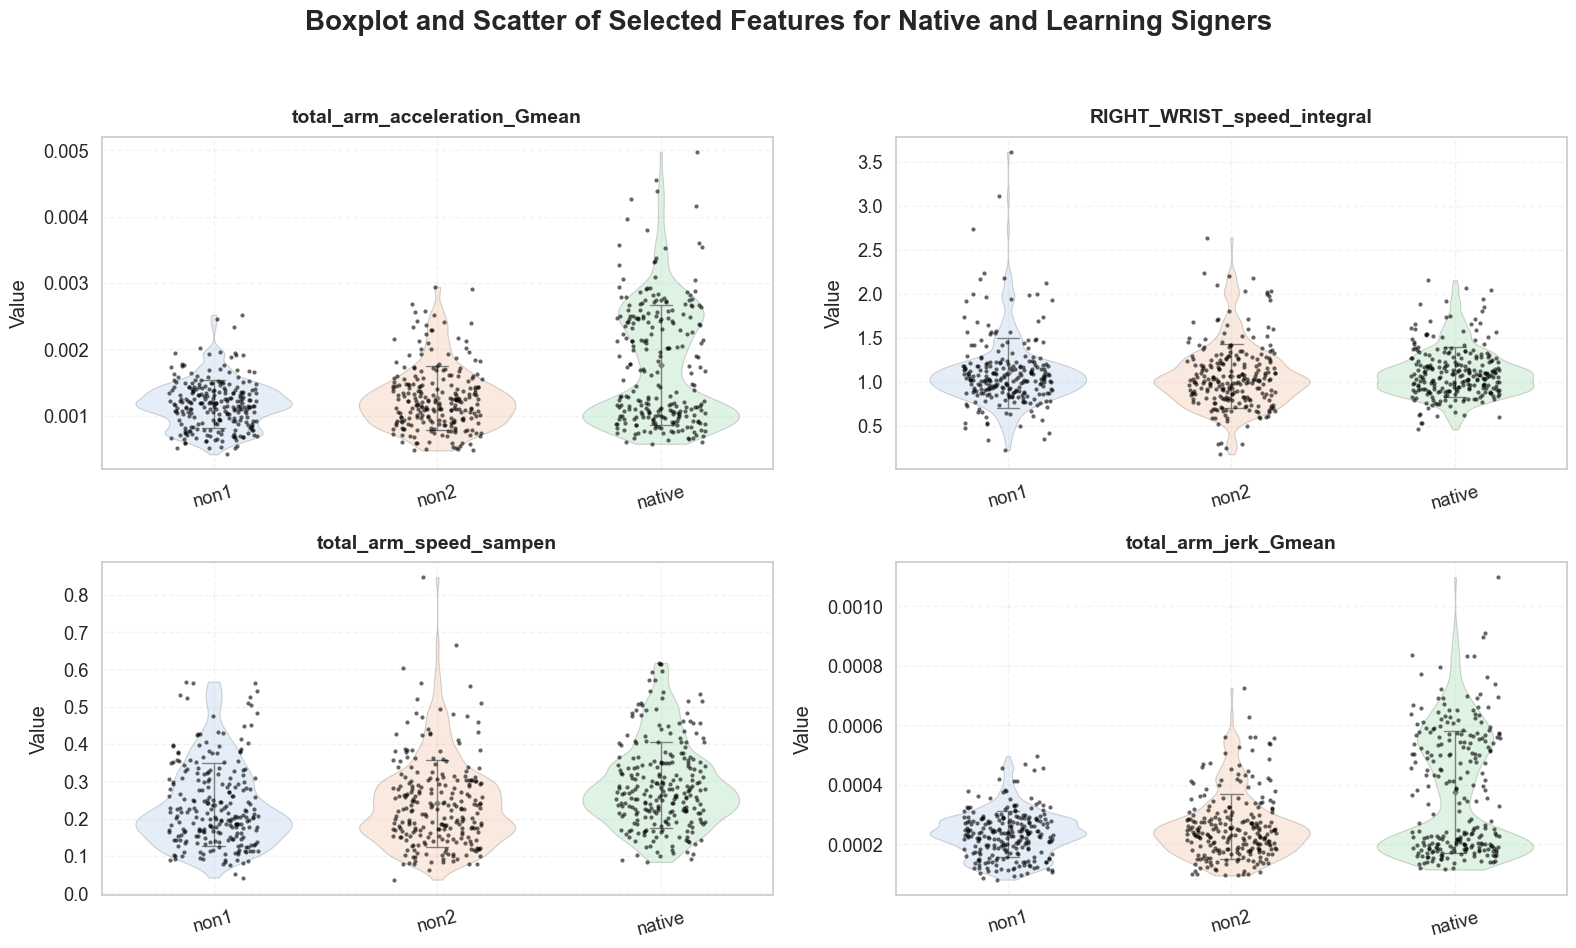

In [147]:
import seaborn as sns
# ignore warnings
import warnings
warnings.filterwarnings("ignore")

featstoplotNN = ['total_arm_acceleration_Gmean',
                 'RIGHT_WRIST_speed_integral',
                 'total_arm_speed_sampen',
                 'total_arm_jerk_Gmean']

def plot_features_halfviolin_scatter(df, features, title):
    sns.set_theme(style="whitegrid", font_scale=1.2)
    palette = sns.color_palette("pastel", df['profID'].nunique())

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
    axes = axes.flatten()

    for i, feature in enumerate(features):
        ax = axes[i]

        # Violin with lighter fill
        sns.violinplot(
            data=df, x='profID', y=feature, ax=ax,
            palette=palette,
            inner=None, cut=0, linewidth=0.8, scale='width',
            bw=.2, orient='v', width=0.7
        )

        # Make violins slightly transparent
        for violin in ax.collections:
            violin.set_alpha(0.3)

        # Swarm or improved strip plot
        sns.stripplot(
            data=df, x='profID', y=feature, ax=ax,
            jitter=0.2, dodge=True, color='black', alpha=0.6, size=3
        )

        # Optional: median line using pointplot
        sns.pointplot(
            data=df, x='profID', y=feature, ax=ax,
            color='gray', ci='sd', join=False, markers='D',
            scale=0.5, errwidth=1, capsize=0.1
        )

        ax.set_title(feature, fontsize=14, weight='semibold', pad=10)
        ax.set_xlabel('')
        ax.set_ylabel('Value', labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.25)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=15)

    plt.suptitle(title, fontsize=20, weight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Plot features for GS
plot_features_halfviolin_scatter(sampled_NN, featstoplotNN, 'Boxplot and Scatter of Selected Features for Native and Learning Signers')


In [ ]:
# plot t
